In [1]:
# データサイズの確認
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../titanic/train.csv")       ## 訓練データ
df_test = pd.read_csv("../titanic/test.csv")   ## テストデータ

print('訓練データのデータ数は{}、変数は{}種類です。'.format(df.shape[0],df.shape[1]))
print('テストデータのデータ数は{}、変数は{}種類です。'.format(df_test.shape[0], df_test.shape[1]))

訓練データのデータ数は891、変数は12種類です。
テストデータのデータ数は418、変数は11種類です。


../titanicで、titanicフォルダの指定ができる

0は行数、1は列数

In [2]:
# 最初の10行の確認
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../titanic/train.csv")        ## 訓練データ
df_test = pd.read_csv("../titanic/test.csv")   ## テストデータ

df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [ ]:
# 欠損値の確認
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../titanic/train.csv")       ## 訓練データ
df_test = pd.read_csv("../titanic/test.csv")   ## テストデータ

df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

<Axes: xlabel='Age', ylabel='Count'>

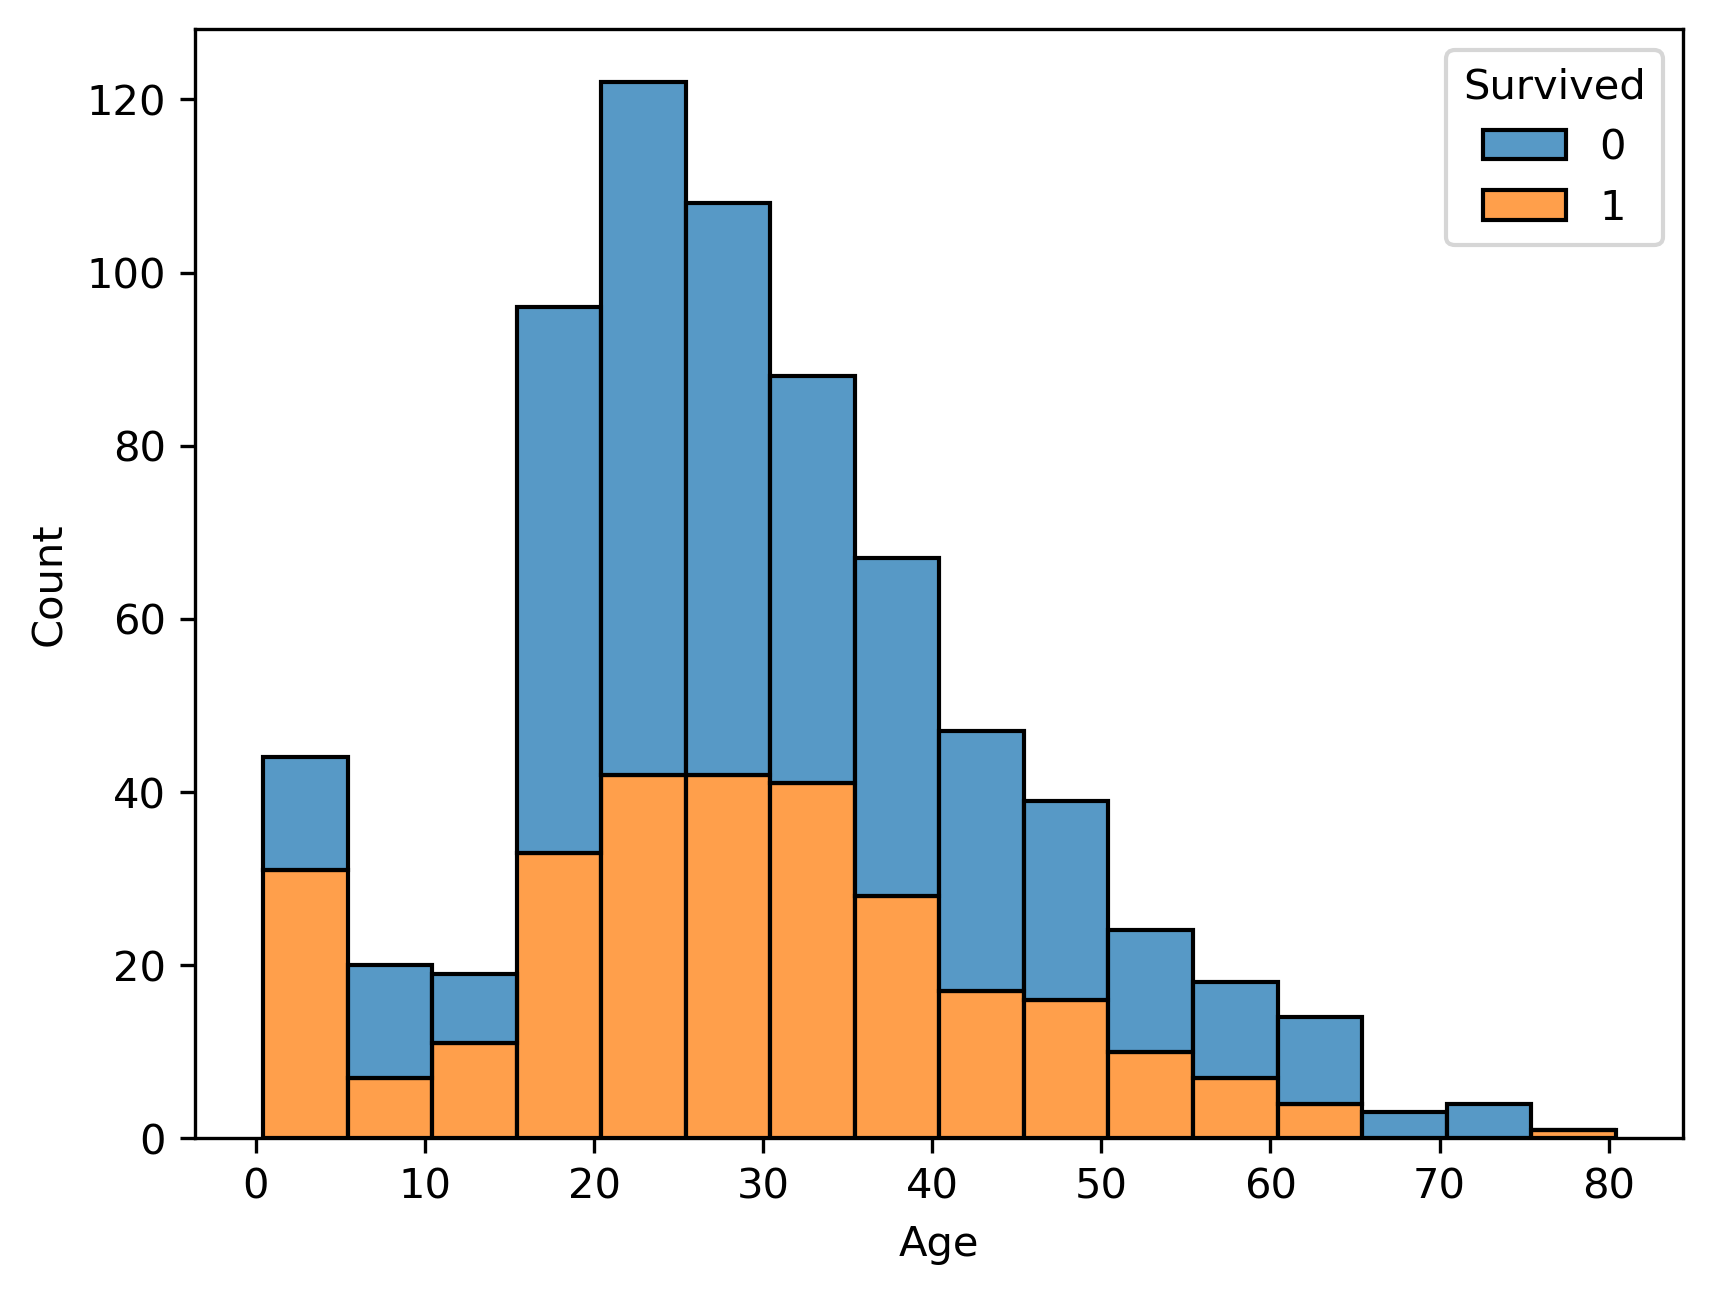

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../titanic/train.csv")       ## 訓練データ
df_test = pd.read_csv("../titanic/test.csv")   ## テストデータ

bin_width=5
bins = np.arange(df["Age"].min(), df["Age"].max() + bin_width, bin_width)
fig, ax= plt.subplots(dpi=300)
sns.histplot(
    data=df,              # 使用するデータ（タイタニックのデータフレーム）
    x="Age",              # 横軸にする項目（年齢）
    hue="Survived",       # ★重要: 色分けする項目（生存フラグ 0 or 1）
    multiple="stack",     # ★重要: 色分けしたデータを「積み上げ（スタック）」にする
    bins=bins,            # さっき作った 5歳刻みの区切りを適用する
    ax=ax                 # 用意した画用紙（ax）の上に描画する
)

## bin_width = 5

グラフの棒の幅を5歳刻みにする



## bins = np.arange(df["Age"].min(), df["Age"].max() + bin_width, bin_width)


np.arange() は、「スタートからストップまで、指定した間隔で数字のリストを作る」 関数


df["Age"].min()（最年少）から df["Age"].max()（最年長）まで、5歳ずつ足した数値を並べた区切り（例: 0, 5, 10, 15...） を作る


Python の数値指定（arange や range）には 「指定した終了値の手前までしか作られない」 というルールがある。
例えば、最年長が 80歳 だったとします。
np.arange(0, 80, 5) と書くと、80の手前（75） で終わってしまい、リストは [0, 5, ..., 75] になってしまいます。

すると、グラフを描く時に 80歳の人（最年長データ）がグラフからはみ出して消えてしまう という問題が発生します！

これを防ぐために、終了値に + bin_width（+5）をしておきます。


もし bin_width = 5（5歳刻み）にしたい場合、3番目の引数（ひきすう）に bin_width を入れないと デフォルトの「1」ずつ増えるリスト になってしまいます。



.min()と.max()は関数だから()をつける必要がある。




## fig, ax = plt.subplots(dpi=300)

グラフを描く画用紙（fig）とグラフの枠組み（ax） を準備
dpi=300 は「高画質・高解像度で綺麗に出力する」という指定（画面で見やすくなる）

データをより詳しく見るため，データの可視化を行っています．
ここでは，例として年齢と生存率の関係を見ています．

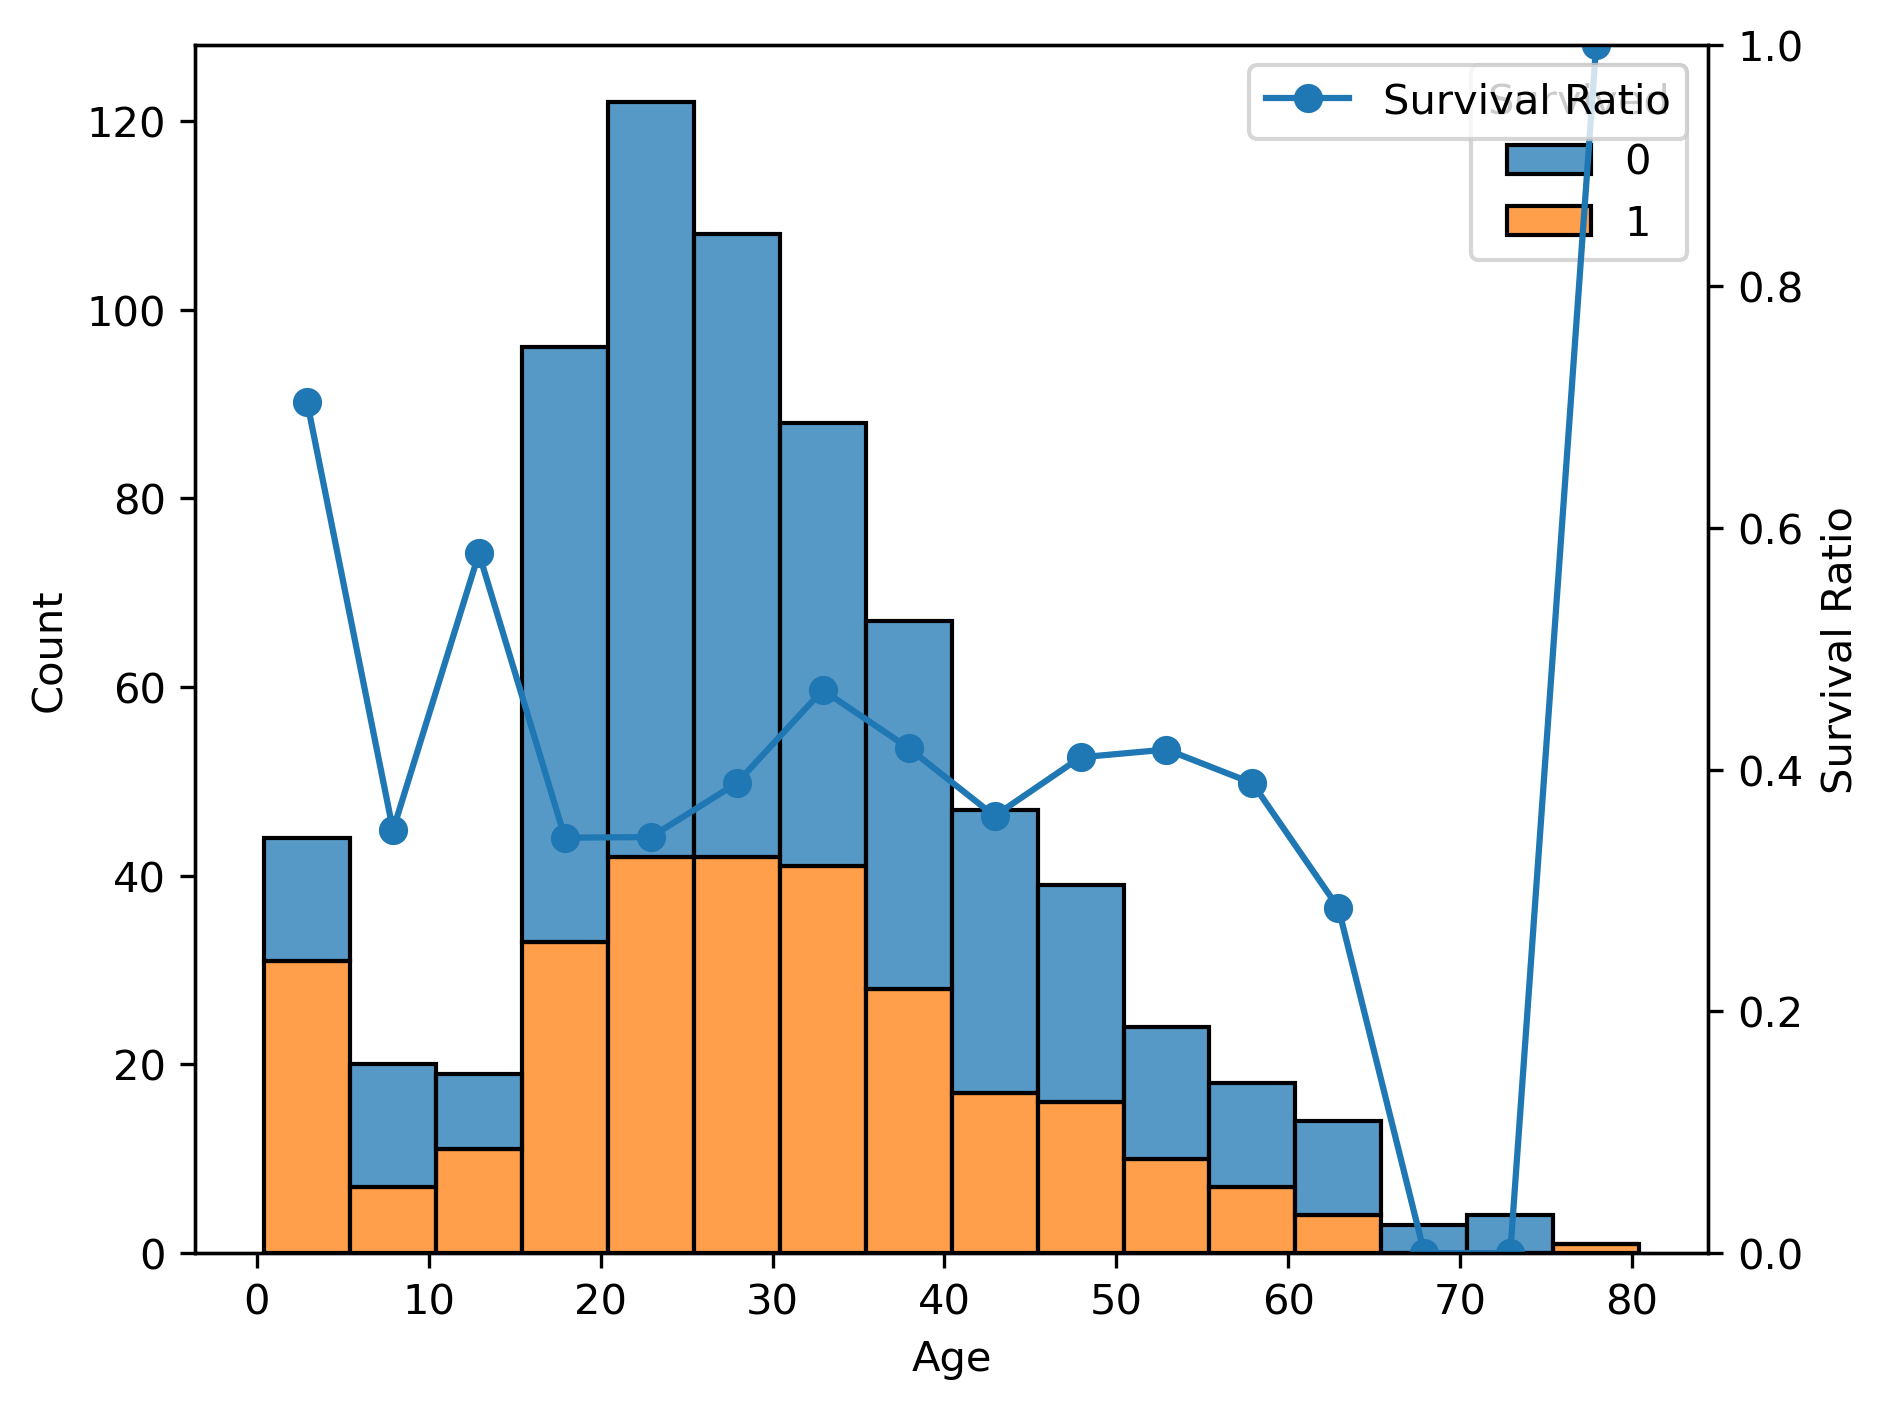

In [7]:
#一時変数でビンごとの生存率を計算

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../titanic/train.csv")       ## 訓練データ
df_test = pd.read_csv("../titanic/test.csv")   ## テストデータ


bin_width=5
bins = np.arange(df["Age"].min(), df["Age"].max() + bin_width, bin_width)
fig, ax= plt.subplots(dpi=300)
sns.histplot(
    data=df,              # 使用するデータ（タイタニックのデータフレーム）
    x="Age",              # 横軸にする項目（年齢）
    hue="Survived",       # ★重要: 色分けする項目（生存フラグ 0 or 1）
    multiple="stack",     # ★重要: 色分けしたデータを「積み上げ（スタック）」にする
    bins=bins,            # さっき作った 5歳刻みの区切りを適用する
    ax=ax                 # 用意した画用紙（ax）の上に描画する
)

age_bins = pd.cut(df["Age"], bins=bins, include_lowest=True)
grouped = pd.crosstab(age_bins, df["Survived"])
ratio = grouped[1] / (grouped[0] + grouped[1])
#ビンの中心を取得
bin_centers = [interval.mid for interval in ratio.index]
#副軸に折れ線をプロット
ax2 = ax.twinx()
ax2.plot(bin_centers, ratio, marker="o", linestyle="-", label="Survival Ratio")
ax2.set_ylabel("Survival Ratio")
ax2.set_ylim(0, 1)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

# age_bins = pd.cut(df["Age"], bins=bins, include_lowest=True)


意味: Age（年齢）のデータを、さっき作った bins（0〜5歳、5〜10歳…などの区切り）のどこに当てはまるか割り振ります。


include_lowest=True は「一番下の値（0歳など）もグループに含める」という指定です。


# grouped = pd.crosstab(age_bins, df["Survived"])

意味: 年齢グループ（縦軸）× 生存フラグ（横軸）の クロス集計表 を作成します。


grouped[0] ＝ 死亡した人数


grouped[1] ＝ 生存した人数

# ratio = grouped[1] / (grouped[0] + grouped[1])


意味: 各年齢グループの 生存率（生存者数 ÷ 全体人数） を計算しています。

結果として、グループごとの生存割合（例: 0.45 ＝ 45%）の数値リストが作られます。

# bin_centers = [interval.mid for interval in ratio.index]

意味: 折れ線の点を 「棒グラフの真ん中」 に打つために、グループの範囲の中央値（例: 0〜5歳なら 2.5歳）を取得しています。

ax2 = ax.twinx()  # ★超重要：左のY軸（人数）とは別に、右側に「2つ目のY軸」を作成する


ax2.plot(bin_centers, ratio, marker="o", linestyle="-", label="Survival Ratio")


ax2.set_ylabel("Survival Ratio")


ax2.set_ylim(0, 1)  # 割合なのでY軸を 0〜1（0%〜100%）に固定


ax2.legend(loc="upper right") # 2軸目の折れ線グラフ（ax2）の凡例（はんれい：グラフの凡例ラベル）を、グラフの右上（upper right）に表示する

ax.twinx(): これを書くことで、X軸（年齢）はそのまま共有しつつ、右側に「生存率専用の縦軸（0.0〜1.0）」を追加 できます。

その右側の軸（ax2）に対して、先ほど計算した生存率の折れ線グラフを描画しています。

上のグラフから右に引きずる形だと分かったので，高い年齢の外れ値をnullにすることで処理します．

一次関数でビンごとの生存率を計算する場合は、fig,ax = plt.subplots(dpi=300)で「ax という名前の新しい画用紙」を用意する必要があることに注意